# Random Forest Project: Breast Cancer Prediction

**Student:** Garvit Singh &nbsp;

**Dataset:** Breast Cancer Prediction Dataset (`Breast_cancer_data.csv`) from **Kaggle** (real data, 569 rows)

**Problem:** Predict whether a tumour is **malignant (0)** or **benign (1)** using 5 measurements: radius, texture, perimeter, area and smoothness. This is a **classification** problem.

**Model:** Random Forest Classifier


## Step 1: Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

## Step 2: Load the dataset

In [2]:
# Upload the file (only works in Google Colab, it is skipped on a normal computer)
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not in Colab, using the file in this folder.")

Saving Breast_cancer_data.csv to Breast_cancer_data (1).csv


In [3]:
df = pd.read_csv("Breast_cancer_data.csv")
df.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


## Step 3: Basic data exploration

In [4]:
# How many rows and columns?
print("Shape:", df.shape)

Shape: (569, 6)


In [5]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   mean_radius      569 non-null    float64
 1   mean_texture     569 non-null    float64
 2   mean_perimeter   569 non-null    float64
 3   mean_area        569 non-null    float64
 4   mean_smoothness  569 non-null    float64
 5   diagnosis        569 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 26.8 KB


In [6]:
# Basic statistics of every column
df.describe()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,1.000000


diagnosis
1    357
0    212
Name: count, dtype: int64


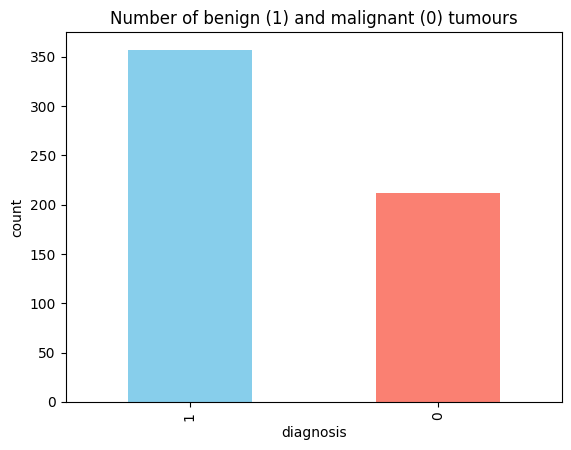

In [7]:
# How many tumours of each type? (0 = malignant, 1 = benign)
print(df["diagnosis"].value_counts())

df["diagnosis"].value_counts().plot(kind="bar", color=["skyblue", "salmon"])
plt.title("Number of benign (1) and malignant (0) tumours")
plt.xlabel("diagnosis")
plt.ylabel("count")
plt.show()

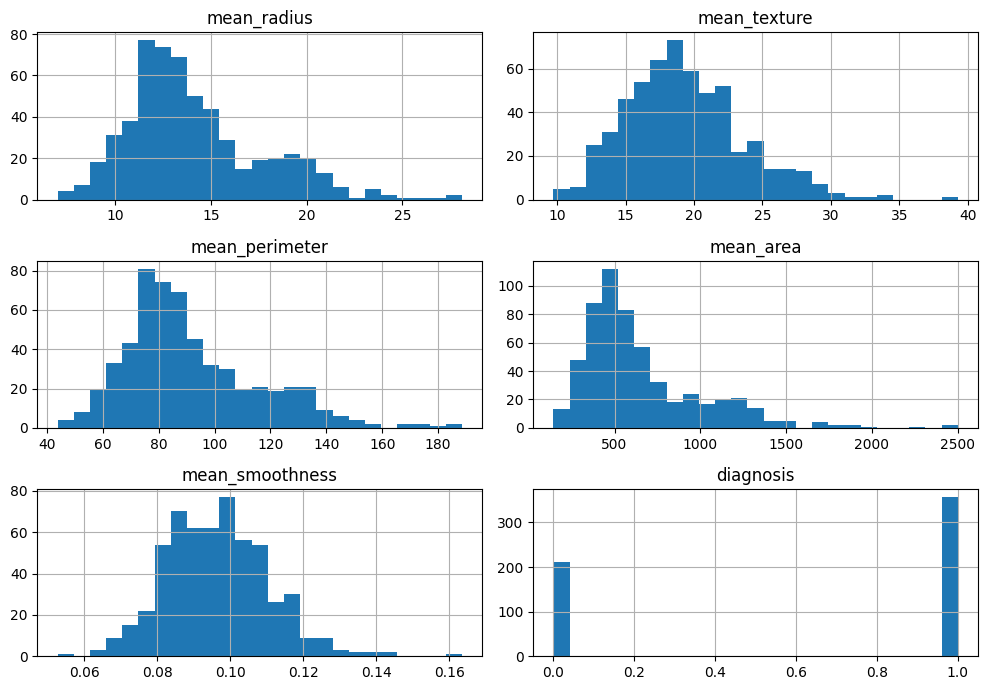

In [8]:
# Histogram of every column
df.hist(figsize=(10, 7), bins=25)
plt.tight_layout()
plt.show()

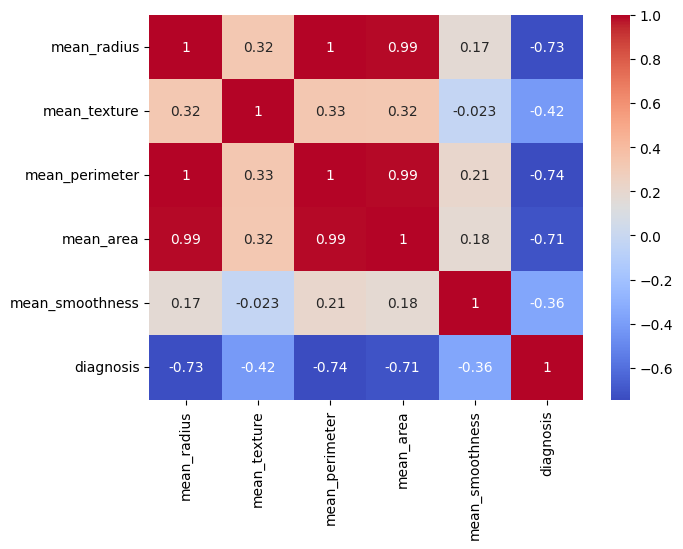

In [9]:
# Correlation heatmap (how strongly columns are related)
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

**What I noticed:**
- There are 357 benign and 212 malignant tumours, so the data is fairly balanced.
- `mean_radius`, `mean_perimeter` and `mean_area` are strongly related to each other, because they all measure the size of the tumour.
- All of the size columns are negatively related to `diagnosis`: bigger tumours are more likely to be malignant (0).

## Step 4: Handle missing values

In [10]:
# Count missing values in each column
df.isnull().sum()

,0
mean_radius,0
mean_texture,0
mean_perimeter,0
mean_area,0
mean_smoothness,0
diagnosis,0


There are **no missing values**, so nothing needs to be filled or removed.

## Step 5: Encode categorical variables

In [11]:
# Check the data type of each column
df.dtypes

,0
mean_radius,float64
mean_texture,float64
mean_perimeter,float64
mean_area,float64
mean_smoothness,float64
diagnosis,int64


All columns are numbers (no text columns), so **no encoding is needed**. The target `diagnosis` is already 0 and 1.

## Step 6: Split features (X) and target (y)

In [12]:
X = df.drop("diagnosis", axis=1)   # input columns
y = df["diagnosis"]                # what we want to predict

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 5)
y shape: (569,)


## Step 7: Train-Test Split

In [13]:
# 80% for training, 20% for testing.
# random_state=42 gives the same split every time.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 455
Testing rows : 114


## Steps 8 & 9: Apply the Random Forest model and train it
A Random Forest is made of many decision trees. Each tree gives a vote and the answer with the most votes wins.

In [14]:
model = RandomForestClassifier(n_estimators=100, random_state=42)   # 100 trees
model.fit(X_train, y_train)                                         # train the model
print("Model trained!")

Model trained!


## Step 10: Make predictions

In [15]:
y_pred = model.predict(X_test)

# Compare the first 10 predictions with the real answers
pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10]})

,Actual,Predicted
0,1,1
1,0,0
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,0,0
8,1,1
9,1,1


## Step 11: Evaluate the model
For this dataset the "positive" class is **1 (benign)**, so precision and recall below are for benign tumours. The classification report at the end shows both classes.

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1-Score :", round(f1, 3))

Accuracy : 0.947
Precision: 0.971
Recall   : 0.944
F1-Score : 0.957


[[41  2]
 [ 4 67]]


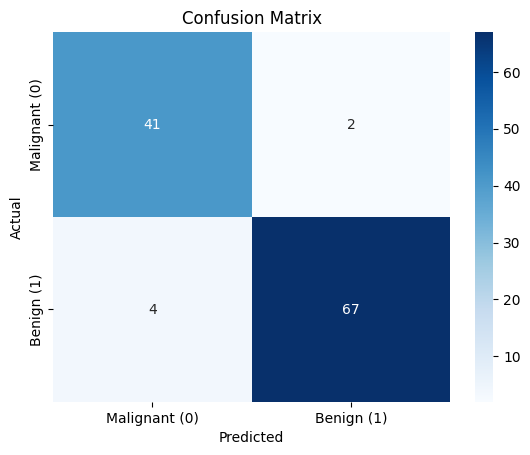

In [17]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Malignant (0)", "Benign (1)"],
            yticklabels=["Malignant (0)", "Benign (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [18]:
# Report for both classes
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

               precision    recall  f1-score   support

Malignant (0)       0.91      0.95      0.93        43
   Benign (1)       0.97      0.94      0.96        71

     accuracy                           0.95       114
    macro avg       0.94      0.95      0.94       114
 weighted avg       0.95      0.95      0.95       114



**How to read this:**
- **Accuracy:** the share of all predictions that are correct.
- **Precision:** when the model says "benign", how often it is right.
- **Recall:** out of all really benign tumours, how many the model found.
- **F1-Score:** a balance between precision and recall.
- **Confusion matrix:** the numbers on the diagonal are correct predictions; the other two numbers are mistakes.

## Step 12: Explain feature importance

In [19]:
importance = pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_})
importance = importance.sort_values("Importance", ascending=False)
importance

,Feature,Importance
2,mean_perimeter,0.293880
3,mean_area,0.258080
0,mean_radius,0.195832
1,mean_texture,0.136820
4,mean_smoothness,0.115388


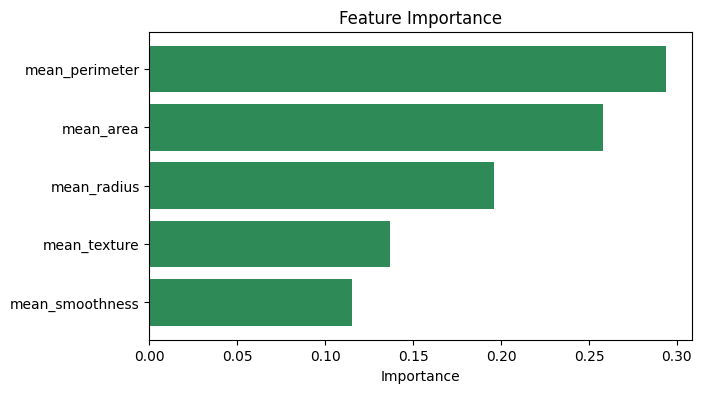

In [20]:
# Feature importance plot
plt.figure(figsize=(7, 4))
plt.barh(importance["Feature"], importance["Importance"], color="seagreen")
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance")
plt.show()

## Bonus 1: Cross Validation
Instead of one train-test split, the data is split 5 different ways and the accuracy is averaged.

In [21]:
scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=5)

print("Scores:", scores.round(3))
print("Average accuracy:", round(scores.mean(), 3))

Scores: [0.895 0.895 0.956 0.965 0.912]
Average accuracy: 0.924


## Bonus 2: Hyperparameter Tuning
GridSearchCV tries different settings and picks the best one (using only the training data).

In [22]:
settings = {"n_estimators": [50, 100, 200],
            "max_depth": [3, 5, 10, None]}

grid = GridSearchCV(RandomForestClassifier(random_state=42), settings, cv=5)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV score:", round(grid.best_score_, 3))

Best settings: {'max_depth': None, 'n_estimators': 50}
Best CV score: 0.921


In [23]:
# Test the tuned model on the test set and compare
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

print("Accuracy of normal model:", round(accuracy_score(y_test, y_pred), 3))
print("Accuracy of tuned model :", round(accuracy_score(y_test, best_pred), 3))

Accuracy of normal model: 0.947
Accuracy of tuned model : 0.947


## Bonus 3: Save the model with Joblib

In [24]:
joblib.dump(model, "random_forest_breast_cancer.joblib")        # save
loaded_model = joblib.load("random_forest_breast_cancer.joblib")  # load again

print("Loaded model gives the same predictions:", (loaded_model.predict(X_test) == y_pred).all())

Loaded model gives the same predictions: True


## Step 13: Conclusion

In this project I used a Random Forest to predict whether a breast tumour is malignant or benign from 5 measurements (radius, texture, perimeter, area and smoothness). The data had no missing values and no text columns, so I only had to split it into X and y and do an 80/20 train-test split.

On the test data (114 patients) the model got an **accuracy of 94.7%**, a **precision of 97.1%**, a **recall of 94.4%** and an **F1-score of 0.957**. The confusion matrix shows 41 malignant and 67 benign tumours were predicted correctly. The model made 6 mistakes: 4 benign tumours were called malignant, and 2 malignant tumours were called benign. The 2 missed cancers are the more serious kind of mistake. Cross-validation gave an average accuracy of 92.4%, which is a bit lower than the test score, so the real accuracy is probably around 92-95%.

**Feature importance:** `mean_perimeter` (29.4%), `mean_area` (25.8%) and `mean_radius` (19.6%) are the most important features. All three measure the size of the tumour, so size is the biggest clue. Texture (13.7%) and smoothness (11.5%) matter less.

**Bonus:** tuning chose 50 trees and no depth limit, and gave the same test accuracy (0.947) as my first model, so the default settings were already good. I also saved the model with Joblib.

**Limitation:** the dataset is small (569 rows) and has only 5 features, so this model is only for learning and **must not be used for real medical diagnosis**.